# QE014: Breaking Symmetry to Think Deeply

**Phases of matter inside neural networks: spontaneous symmetry breaking carries information through deep networks,
and decides what a diffusion model generates.**

Two puzzles of modern deep learning have a physics flavour:

1. **Depth.** A signal passing through many layers tends either to die out or to scramble into noise. Engineering
   tricks (skip connections, normalisation) fix this. Is there a *principle* that does?
2. **Generation.** A diffusion model turns pure noise into an image. At some moment each sample must *decide* what it
   becomes. When does that happen, and does the model create something new or copy its training data?

Physics has a shared answer: **spontaneous symmetry breaking**. A magnet cooled below its critical temperature must
pick a direction, and if the symmetry is continuous, it gains slow, long-lived modes (**Goldstone modes**) that carry
information over long distances.

* **Part A (one exact answer, Euler-style):** the "magnetisation" of an infinitely wide, rotation-symmetric deep
  network, from mean-field theory.
* **Part B1:** the network's phase transition, theory against simulation.
* **Part B2:** a Goldstone mode that remembers the input through 100 layers while ordinary correlations are forgotten.
* **Part B3:** train 64-layer networks with no skip connections and no normalisation. Symmetric networks train, ordinary
  ones do not.
* **Part B4:** symmetry breaking in a diffusion model, and the line between memorising and generalising.
* **Animations:** samples splitting into two worlds during generation, and copying versus creating in 2D.

### Words used in this notebook

| term | meaning |
|---|---|
| **layer / depth / width** | a network applies L layers in a row (depth); each layer has N units (width) |
| **weights, σ_W** | the numbers each layer multiplies by; σ_W sets their typical size at the start of training |
| **nonlinearity** | the function applied after each layer (here a tanh that squashes size) |
| **signal propagation** | how the size and shape of a representation change as it passes through layers |
| **symmetry / equivariance** | a transformation that changes nothing important. A layer is **equivariant** if rotating its input rotates its output in the same way |
| **U(1), O(k)** | rotations of a complex number's phase (a circle) / rotations of a k-dimensional vector |
| **order parameter** | a number that is zero in the symmetric phase and nonzero once the symmetry breaks (like a magnet's magnetisation) |
| **spontaneous symmetry breaking (SSB)** | the rules are symmetric, but the state picks a direction anyway |
| **Goldstone mode** | the slow "direction" mode that appears when a *continuous* symmetry breaks; it costs nothing to move along it, so it survives |
| **mean-field theory** | the exact description of an infinitely wide network, where averages replace randomness |
| **diffusion model** | a generator that learns to reverse a process that slowly turns data into noise |
| **score** | the direction in which data becomes more likely; a diffusion model learns it to steer noise back to data |
| **memorisation / generalisation** | reproducing training examples exactly / producing new examples of the same kind |
| **pitchfork bifurcation** | one stable state splitting into two, the mathematical form of symmetry breaking |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `scipy`, `pandas`, `matplotlib`, `scikit-learn` and `torch` (CPU is enough). It runs in
about five minutes and writes two GIF animations next to itself.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.integrate import quad
from scipy.optimize import brentq
import torch
from sklearn.datasets import load_digits

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK, BG = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b", "#fcfcfb"
rng = np.random.default_rng(14)                                  # random seed
torch.set_num_threads(2)

## Part A: the magnetisation of a deep network

A **U(1)-equivariant** layer works with complex activations $z \in \mathbb C^N$:

$$z^{\,l+1} = W^l\,\phi(z^l), \qquad \phi(z) = \tanh(|z|)\,\frac{z}{|z|},$$

with complex weights $W^l_{ij}$ drawn at random with $\mathbb E|W_{ij}|^2 = \sigma_W^2/N$ and no bias. The nonlinearity
squashes each unit's *size* but keeps its *phase*, so multiplying the input by $e^{i\theta}$ multiplies every layer by
$e^{i\theta}$: the network is symmetric under rotating all phases.

The **order parameter** is the average squared activation $c^l = \frac1N\sum_i |z^l_i|^2$. For infinite width each
$z_i$ is a complex Gaussian, $|z_i|^2$ is exponential with mean $c^l$, and

$$c^{l+1} = \sigma_W^2\;\mathbb E\big[\tanh^2|z|\big] = \sigma_W^2 \int_0^\infty 2u\,e^{-u^2}\,\tanh^2\!\big(u\sqrt{c^l}\big)\,du .$$

For small $c$, $\tanh^2 x \approx x^2$ gives $c^{l+1} \approx \sigma_W^2 c^l$. So for $\sigma_W < 1$ the signal dies
($c^\ast = 0$: the symmetric phase), and for $\sigma_W > 1$ it settles at a nonzero value $c^\ast$: the symmetry is
broken.

**Task:** for $\sigma_W = 2$, find the nonzero fixed point $c^\ast$ and report

$$A = \lfloor 10^6\, c^\ast \rfloor .$$

*Check value:* just above the transition, $\sigma_W = 1.1$ gives $c^\ast = 0.165008\ldots$, close to the leading-order
estimate $\tfrac34(\sigma_W^2 - 1) = 0.1575$.

In [2]:
def mean_tanh2(c):
    return quad(lambda u: 2 * u * np.exp(-u * u) * np.tanh(u * np.sqrt(c)) ** 2, 0, np.inf,
                epsabs=1e-14, epsrel=1e-13)[0]

def fixed_point(sw):
    return brentq(lambda c: sw ** 2 * mean_tanh2(c) - c, 1e-9, 100, xtol=1e-15) if sw > 1 else 0.0

print(f"check, sigma_W = 1.1: c* = {fixed_point(1.1):.9f}   (leading order {0.75 * (1.1 ** 2 - 1):.4f})")
c_star = fixed_point(2.0)
c = 1.0
for _ in range(100):                                             # iterate the layer map as a second check
    c = 4 * mean_tanh2(c)
print(f"sigma_W = 2.0: root finding c* = {c_star:.10f},  100 layers of iteration: {c:.10f}")
A = int(np.floor(1e6 * c_star))
print(f"\nANSWER  A = {A}")

check, sigma_W = 1.1: c* = 0.165008260   (leading order 0.1575)
sigma_W = 2.0: root finding c* = 2.7590050827,  100 layers of iteration: 2.7590050827

ANSWER  A = 2759005


**Check with a real (finite) network.** Push random inputs through 100 random U(1) layers of width 2,000 and measure
$c$ at the end.

In [3]:
def random_u1_net(x, sw, L, N, gen):
    z = x
    for _ in range(L):
        W = (gen.standard_normal((N, N)) + 1j * gen.standard_normal((N, N))) * sw / np.sqrt(2 * N)
        a = np.abs(z); z = W @ (np.tanh(a) * z / np.maximum(a, 1e-12))
    return z

N_sim = 2000
z0 = (rng.standard_normal(N_sim) + 1j * rng.standard_normal(N_sim)) / np.sqrt(2)
zL = random_u1_net(z0, 2.0, 100, N_sim, rng)
print(f"finite network (N = {N_sim}, 100 layers): c = {np.mean(np.abs(zL) ** 2):.4f}   mean-field c* = {c_star:.4f}")

finite network (N = 2000, 100 layers): c = 2.7397   mean-field c* = 2.7590


## Part B1: a phase transition inside the network

Scan $\sigma_W$ and compare the mean-field $c^\ast$ with simulations of width-500 networks after 100 layers.

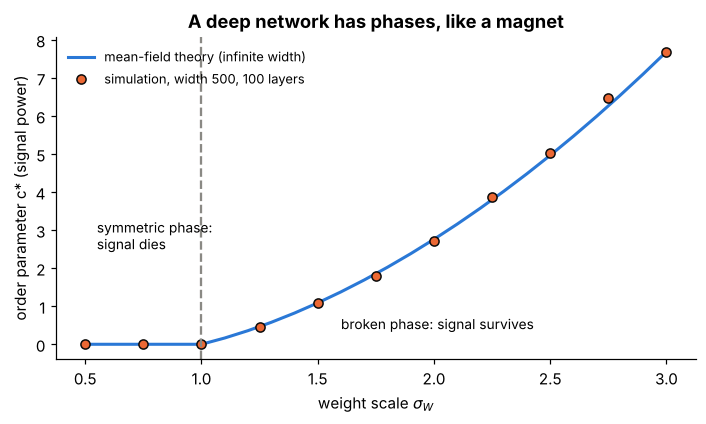

In [4]:
sws = np.linspace(0.5, 3.0, 26)
theory = [fixed_point(s) for s in sws]
sim_sw = np.linspace(0.5, 3.0, 11)
sim = [np.mean([np.mean(np.abs(random_u1_net((rng.standard_normal(500) + 1j * rng.standard_normal(500)) / np.sqrt(2),
                                            s, 100, 500, rng)) ** 2) for _ in range(3)]) for s in sim_sw]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(sws, theory, color=BLUE, lw=2, label="mean-field theory (infinite width)")
ax.plot(sim_sw, sim, "o", color=ORANGE, mec=INK, label="simulation, width 500, 100 layers")
ax.axvline(1, color=GRAY, ls="--"); ax.text(0.55, 2.5, "symmetric phase:\nsignal dies", fontsize=9)
ax.text(1.6, 0.4, "broken phase: signal survives", fontsize=9)
ax.set_xlabel(r"weight scale $\sigma_W$"); ax.set_ylabel("order parameter c* (signal power)")
ax.legend(frameon=False, fontsize=8.5, loc="upper left"); ax.set_title("A deep network has phases, like a magnet")
plt.show()

## Part B2: the Goldstone mode remembers

What happens to the *relationship* between two inputs as they travel through depth?

* **Ordinary network** (real tanh units, same weight scale): send two inputs with correlation $\rho_0$. Deep down,
  their correlation shrinks towards zero and gets scrambled, so the network loses much of how they were related.
* **U(1) network:** send two complex inputs related by a phase $\varphi_0$ (and only 90% correlated). Their overlap
  $q = \frac1N\sum_i z_{a,i}\,\overline{z_{b,i}} = |q|\,e^{i\varphi}$ has a magnitude that also shrinks with depth, but a
  phase $\varphi$ that is protected by the symmetry. This is the Goldstone mode: rotating the relative phase costs
  nothing, so nothing pushes it back.

We work close to the transition ($\sigma_W = 1.2$), where the overlap decays slowly enough to measure its phase after
100 layers. Far above the transition, at $\sigma_W = 2$, the overlap shrinks to the size of finite-width noise within
about 40 layers, and its phase can no longer be read. One random network of width 1,500 carries 13 input pairs.

propagated 26 input pairs through two 100-layer networks of width 1500 in 17 s


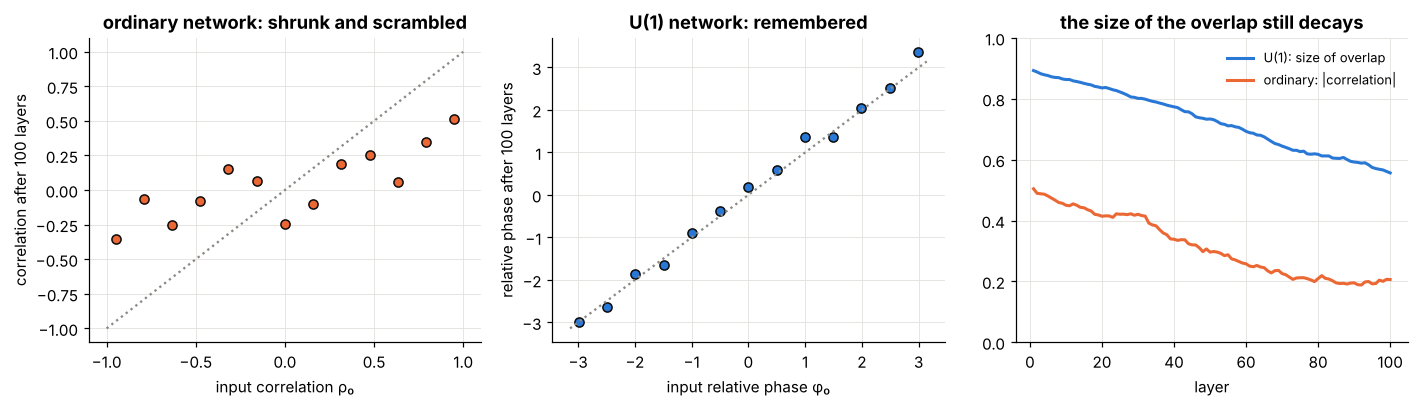

U(1): phase error after 100 layers: median 0.12 rad, largest 0.39 rad
ordinary: input correlation 0.95 -> 0.51, -0.95 -> -0.35; correlation between input and output values across pairs: 0.80


In [5]:
N_P, L_P, SW_P = 1500, 100, 1.2                                  # close to the transition: long memory
phis = np.linspace(-0.95 * np.pi, 0.95 * np.pi, 13); rhos = np.linspace(-0.95, 0.95, 13)
za = (rng.standard_normal((N_P, 13)) + 1j * rng.standard_normal((N_P, 13))) / np.sqrt(2)
extra = (rng.standard_normal((N_P, 13)) + 1j * rng.standard_normal((N_P, 13))) / np.sqrt(2)
Z = np.concatenate([za, np.exp(-1j * phis) * (0.9 * za + np.sqrt(0.19) * extra)], 1)   # 13 pairs, 90% correlated
xa = rng.standard_normal((N_P, 13))
Xr = np.concatenate([xa, rhos * xa + np.sqrt(1 - rhos ** 2) * rng.standard_normal((N_P, 13))], 1)
phi_u1 = lambda z: np.tanh(np.abs(z)) * z / np.maximum(np.abs(z), 1e-12)
overlap_u1, overlap_real = [], []
t0 = time.time()
for _ in range(L_P):                                             # one random network, all pairs pass through it
    W = (rng.standard_normal((N_P, N_P)) + 1j * rng.standard_normal((N_P, N_P))) * SW_P / np.sqrt(2 * N_P)
    Z = W @ phi_u1(Z)
    Xr = (rng.standard_normal((N_P, N_P)) * SW_P / np.sqrt(N_P)) @ np.tanh(Xr)
    a, b = Z[:, :13], Z[:, 13:]
    overlap_u1.append(np.sum(a * b.conj(), 0) / np.sqrt(np.sum(abs(a) ** 2, 0) * np.sum(abs(b) ** 2, 0)))
    a, b = Xr[:, :13], Xr[:, 13:]
    overlap_real.append(np.sum(a * b, 0) / np.sqrt(np.sum(a ** 2, 0) * np.sum(b ** 2, 0)))
overlap_u1, overlap_real = np.array(overlap_u1), np.array(overlap_real)
print(f"propagated 26 input pairs through two {L_P}-layer networks of width {N_P} in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(rhos, overlap_real[-1], "o", color=ORANGE, mec=INK); ax[0].plot([-1, 1], [-1, 1], ":", color=GRAY)
ax[0].set_xlabel("input correlation ρ₀"); ax[0].set_ylabel("correlation after 100 layers")
ax[0].set_title("ordinary network: shrunk and scrambled")
out_phase = np.angle(overlap_u1[-1]); out_phase = phis + np.angle(np.exp(1j * (out_phase - phis)))  # unwrap near ±π
ax[1].plot(phis, out_phase, "o", color=BLUE, mec=INK); ax[1].plot([-np.pi, np.pi], [-np.pi, np.pi], ":", color=GRAY)
ax[1].set_xlabel("input relative phase φ₀"); ax[1].set_ylabel("relative phase after 100 layers")
ax[1].set_title("U(1) network: remembered")
ax[2].plot(np.arange(1, L_P + 1), np.mean(np.abs(overlap_u1), 1), color=BLUE, lw=2, label="U(1): size of overlap")
ax[2].plot(np.arange(1, L_P + 1), np.mean(np.abs(overlap_real), 1), color=ORANGE, lw=2, label="ordinary: |correlation|")
ax[2].set_ylim(0, 1); ax[2].set_xlabel("layer"); ax[2].legend(frameon=False, fontsize=8.5)
ax[2].set_title("the size of the overlap still decays")
for a in ax:
    a.grid(color="#e4e3df", lw=0.6)
plt.tight_layout(); plt.show()
err = np.abs(np.angle(np.exp(1j * (np.angle(overlap_u1[-1]) - phis))))
print(f"U(1): phase error after {L_P} layers: median {np.median(err):.2f} rad, largest {err.max():.2f} rad")
print(f"ordinary: input correlation 0.95 -> {overlap_real[-1][-1]:.2f}, -0.95 -> {overlap_real[-1][0]:.2f};"
      f" correlation between input and output values across pairs: {np.corrcoef(rhos, overlap_real[-1])[0, 1]:.2f}")

The ordinary network keeps only a shrunken, noisy trace of its inputs: a correlation of 0.95 comes out near 0.5, and
nearby inputs can swap order. The U(1) network returns each input phase after 100 layers to within a few tenths of a
radian (the errors printed above), although the *size* of the overlap shrinks too. The symmetry pins the phase, so
nothing drags it towards a preferred value. The symmetry
protects a channel that ordinary networks do not have.

## Part B3: training very deep networks without tricks

Classify handwritten digits (8×8 images, 10 classes) with **64 hidden layers**, **no skip connections and no
normalisation**, at several weight scales $\sigma_W$. Three networks, each with 64 real numbers per layer:

* **ordinary:** 64 real tanh units;
* **U(1):** 32 complex units with the phase-keeping nonlinearity;
* **O(4):** 16 blocks of 4 real numbers; the weights mix whole blocks ($W \otimes I_4$), and the nonlinearity squashes
  each block's length.

Input and output layers are ordinary, so the network can *use* the broken symmetry rather than being bound by it. Each
network trains for 15 epochs with Adam.

In [6]:
digits = load_digits(); X = (digits.data / 16.0).astype(np.float32); y = digits.target
perm = np.random.default_rng(0).permutation(len(X)); n_train = 1300
Xtr, ytr = torch.tensor(X[perm[:n_train]]), torch.tensor(y[perm[:n_train]])
Xte, yte = torch.tensor(X[perm[n_train:]]), torch.tensor(y[perm[n_train:]])

class Ordinary(torch.nn.Module):
    def __init__(self, L, sw, N=64):
        super().__init__(); self.inp, self.out = torch.nn.Linear(64, N), torch.nn.Linear(N, 10)
        self.W = torch.nn.ParameterList([torch.nn.Parameter(torch.randn(N, N) * sw / np.sqrt(N)) for _ in range(L)])
    def forward(self, x):
        h = self.inp(x)
        for W in self.W:
            h = torch.tanh(h) @ W.T
        return self.out(torch.tanh(h))

def radial(h, dim=-1):
    r = h.norm(dim=dim, keepdim=True); return h * torch.tanh(r) / (r + 1e-8)

class U1(torch.nn.Module):
    def __init__(self, L, sw, N=32):
        super().__init__(); self.N = N
        self.inp, self.out = torch.nn.Linear(64, 2 * N), torch.nn.Linear(2 * N, 10)
        make = lambda: torch.nn.Parameter(torch.randn(N, N) * sw / np.sqrt(2 * N))
        self.Wr = torch.nn.ParameterList([make() for _ in range(L)]); self.Wi = torch.nn.ParameterList([make() for _ in range(L)])
    def forward(self, x):
        h = self.inp(x); z = torch.complex(h[:, :self.N], h[:, self.N:])
        phi = lambda z: z * (torch.tanh(z.abs()) / (z.abs() + 1e-8))
        for Wr, Wi in zip(self.Wr, self.Wi):
            z = phi(z) @ torch.complex(Wr, Wi).T
        z = phi(z)
        return self.out(torch.cat([z.real, z.imag], 1))

class Ok(torch.nn.Module):
    def __init__(self, L, sw, N=16, k=4):
        super().__init__(); self.N, self.k = N, k
        self.inp, self.out = torch.nn.Linear(64, N * k), torch.nn.Linear(N * k, 10)
        self.W = torch.nn.ParameterList([torch.nn.Parameter(torch.randn(N, N) * sw / np.sqrt(N)) for _ in range(L)])
    def forward(self, x):
        h = self.inp(x).view(-1, self.N, self.k)
        for W in self.W:
            h = torch.einsum("ij,bjk->bik", W, radial(h))
        return self.out(radial(h).reshape(len(x), -1))

def train(model, epochs=15):
    opt = torch.optim.Adam(model.parameters(), 1e-3); g = torch.Generator().manual_seed(0)
    for _ in range(epochs):
        order = torch.randperm(n_train, generator=g)
        for k in range(0, n_train, 64):
            b = order[k:k + 64]; opt.zero_grad()
            torch.nn.functional.cross_entropy(model(Xtr[b]), ytr[b]).backward(); opt.step()
    with torch.no_grad():
        return (model(Xte).argmax(1) == yte).float().mean().item()

DEPTH = 64
t0 = time.time(); rows = []
for sw in [0.5, 1.0, 1.5, 2.0, 3.0]:
    row = {"σ_W": sw}
    for name, cls in [("ordinary tanh", Ordinary), ("U(1)", U1), ("O(4)", Ok)]:
        torch.manual_seed(1); row[name] = train(cls(DEPTH, sw))
    rows.append(row)
acc = pd.DataFrame(rows).set_index("σ_W")
params = {name: sum(p.numel() for p in cls(DEPTH, 1.0).parameters()) for name, cls in
          [("ordinary tanh", Ordinary), ("U(1)", U1), ("O(4)", Ok)]}
print(f"trained 15 networks in {time.time() - t0:.0f} s;  parameters: {params}")
(100 * acc).round(1).rename(columns=lambda c: c + " test accuracy (%)")

trained 15 networks in 89 s;  parameters: {'ordinary tanh': 266954, 'U(1)': 135882, 'O(4)': 21194}


,ordinary tanh test accuracy (%),U(1) test accuracy (%),O(4) test accuracy (%)
σ_W,,,
0.5,8.0,8.0,8.0
1.0,8.5,63.8,94.6
1.5,10.1,56.7,94.4
2.0,31.4,48.5,92.6
3.0,9.1,11.5,76.9


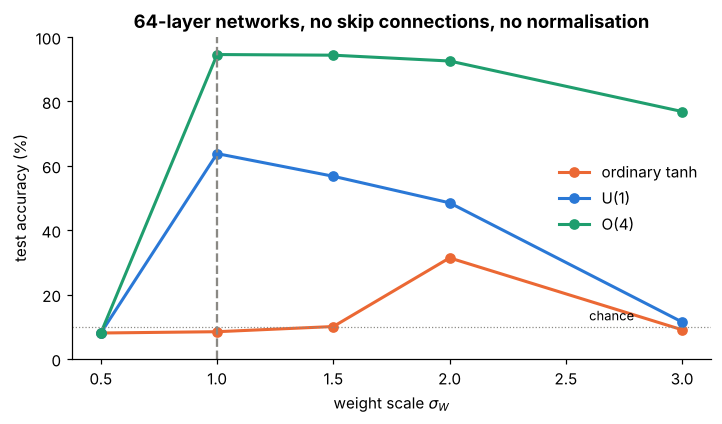

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, col in [("ordinary tanh", ORANGE), ("U(1)", BLUE), ("O(4)", GREEN)]:
    ax.plot(acc.index, 100 * acc[name], "o-", color=col, lw=2, label=name)
ax.axvline(1, color=GRAY, ls="--"); ax.axhline(10, color=GRAY, lw=0.8, ls=":"); ax.text(2.6, 12, "chance", fontsize=8.5)
ax.set_xlabel(r"weight scale $\sigma_W$"); ax.set_ylabel("test accuracy (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False); ax.set_title(f"{DEPTH}-layer networks, no skip connections, no normalisation"); plt.show()

Below $\sigma_W = 1$ (the symmetric phase) nothing trains: the signal dies before reaching the output. Above it, the
ordinary network stays far behind (31% at best), because its signal scrambles into noise. The symmetric networks train, and the O(4)
network reaches over 90% test accuracy with the fewest parameters of the three. The broken continuous symmetry gives
the gradient a protected path through depth.

## Part B4: symmetry breaking in a diffusion model

A diffusion model learns to undo the noising process
$x_t = e^{-t}x_0 + \sqrt{1 - e^{-2t}}\;\varepsilon$. Starting from noise at large $t$, it runs the **reverse** process

$$x_{t-\Delta t} = x_t + \big[x_t + 2\,s_t(x_t)\big]\Delta t + \sqrt{2\Delta t}\;\xi,$$

where $s_t = \nabla\log p_t$ is the **score**. To see the physics cleanly we use the *exact* score of simple data sets.

**1D: two data points at ±m.** The noisy distribution $p_t$ is a mixture of two Gaussians centred at $\pm m e^{-t}$
with variance $1 - e^{-2t}$. Its "potential" $U_t = -\log p_t$ has a single well at large $t$ and two wells at small
$t$. The switch happens when the curvature at $x = 0$ changes sign, $m^2 e^{-2t} = 1 - e^{-2t}$:

$$t_c = \tfrac12\ln(1 + m^2).$$

Before $t_c$ a sample has no reason to prefer either side; after it, it has to choose. This is a **pitchfork
bifurcation**, which is spontaneous symmetry breaking during generation.

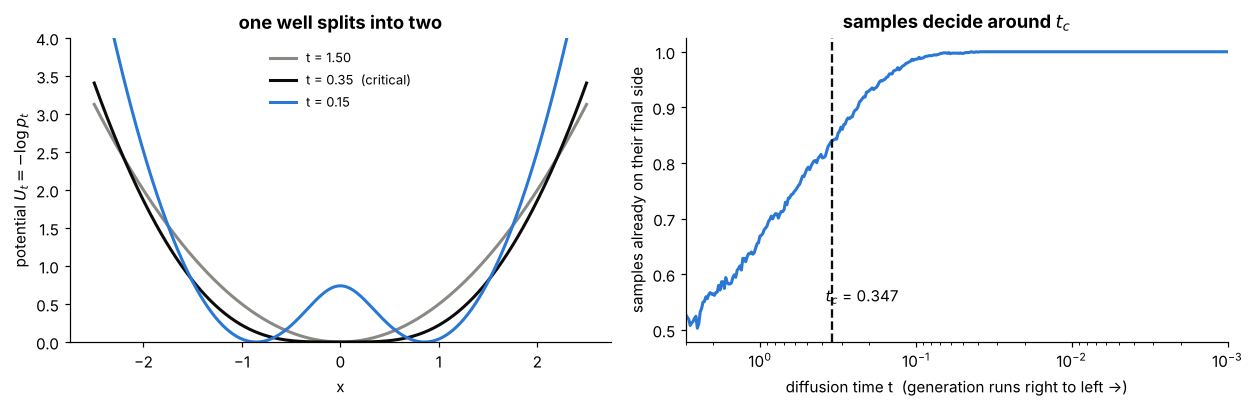

t_c = 0.3466;  committed at 2 t_c: 0.73, at t_c/2: 0.94


In [8]:
M = 1.0
t_c = 0.5 * np.log(1 + M ** 2)

def score_two_points(x, t, m=M):
    mu, var = m * np.exp(-t), 1 - np.exp(-2 * t)
    return (-x + mu * np.tanh(mu * x / var)) / var                  # exact d/dx log p_t

def reverse_diffusion(score, x, T=3.0, steps=600, t_min=1e-5, keep=False):
    ts = np.geomspace(T, t_min, steps + 1); path = [x.copy()]
    for k in range(steps):
        t, dt = ts[k], ts[k] - ts[k + 1]
        x = x + (x + 2 * score(x, t)) * dt + np.sqrt(2 * dt) * rng.standard_normal(x.shape)
        if keep:
            path.append(x.copy())
    return (x, ts, np.array(path)) if keep else x

x_final, ts, paths = reverse_diffusion(score_two_points, rng.standard_normal(2000), keep=True)
final_side = np.sign(paths[-1])
committed = np.mean(np.sign(paths) == final_side, axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
xs = np.linspace(-2.5, 2.5, 400)
for t_, col in [(1.5, GRAY), (t_c, INK), (0.15, BLUE)]:
    mu, var = M * np.exp(-t_), 1 - np.exp(-2 * t_)
    U = -np.log(0.5 * np.exp(-(xs - mu) ** 2 / (2 * var)) + 0.5 * np.exp(-(xs + mu) ** 2 / (2 * var)))
    ax[0].plot(xs, U - U.min(), color=col, lw=2, label=f"t = {t_:.2f}" + ("  (critical)" if t_ == t_c else ""))
ax[0].set_ylim(0, 4); ax[0].set_xlabel("x"); ax[0].set_ylabel(r"potential $U_t = -\log p_t$")
ax[0].legend(frameon=False, fontsize=8.5); ax[0].set_title("one well splits into two")
ax[1].semilogx(ts, committed, color=BLUE, lw=2)
ax[1].axvline(t_c, color=INK, ls="--"); ax[1].text(t_c * 1.1, 0.55, f"$t_c$ = {t_c:.3f}")
ax[1].set_xlim(3, 1e-3); ax[1].set_xlabel("diffusion time t  (generation runs right to left →)")
ax[1].set_ylabel("samples already on their final side"); ax[1].set_title("samples decide around $t_c$")
plt.tight_layout(); plt.show()
print(f"t_c = {t_c:.4f};  committed at 2 t_c: {np.interp(2 * t_c, ts[::-1], committed[::-1]):.2f},"
      f" at t_c/2: {np.interp(t_c / 2, ts[::-1], committed[::-1]):.2f}")

**2D: copying versus creating.** Training data: 16 points on a circle. With the *exact* score of these 16 points, a
diffusion model can only ever reproduce them: it memorises. Real networks cannot represent such a sharp score and
effectively smooth it. We model that by blurring every training point with a Gaussian of width $h$, which keeps the
score exact for the blurred data. How many samples are copies (within 0.03 of a training point), and how many still lie
on the circle (within 0.1)?

In [9]:
angles = np.linspace(0, 2 * np.pi, 16, endpoint=False) + 0.1 * rng.standard_normal(16)
train_pts = np.c_[np.cos(angles), np.sin(angles)]

def make_score(h):
    def score(x, t):
        mu = np.exp(-t) * train_pts; var = 1 - np.exp(-2 * t) + np.exp(-2 * t) * h ** 2
        d = x[:, None, :] - mu[None]; logw = -np.sum(d ** 2, -1) / (2 * var)
        w = np.exp(logw - logw.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)
        return -np.einsum("nk,nkd->nd", w, d) / var
    return score

rows = []; samples = {}
for h in [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]:
    xs_ = reverse_diffusion(make_score(h), rng.standard_normal((1500, 2)), steps=500)
    nearest = np.min(np.linalg.norm(xs_[:, None] - train_pts[None], axis=-1), 1)
    on_circle = np.abs(np.linalg.norm(xs_, axis=1) - 1) < 0.1
    rows.append({"blur h": h, "copies of training points (%)": 100 * np.mean(nearest < 0.03),
                 "on the circle (%)": 100 * np.mean(on_circle),
                 "new and on the circle (%)": 100 * np.mean(on_circle & (nearest >= 0.03))})
    samples[h] = xs_
gen_table = pd.DataFrame(rows).set_index("blur h").round(1)
gen_table

,copies of training points (%),on the circle (%),new and on the circle (%)
blur h,,,
0.00,100.0,100.0,0.0
0.05,17.0,95.1,78.1
0.10,4.1,67.1,63.0
0.20,1.9,39.8,37.9
0.30,1.5,25.9,24.5
0.50,0.9,16.3,15.5


With the exact score every sample is a copy of a training point. A little smoothing (h = 0.05) makes about three
quarters of the samples genuinely new points on the circle; too much smoothing loses the circle itself. Generalisation sits in between, and the amount of smoothing a network
supplies (through its architecture and training) decides where a model lands.

## Animations

**1. Generation as symmetry breaking.** Left: the potential $U_t$ and where the samples are; right: their paths, coloured
by the side they end on. Watch the single well split at $t_c$.

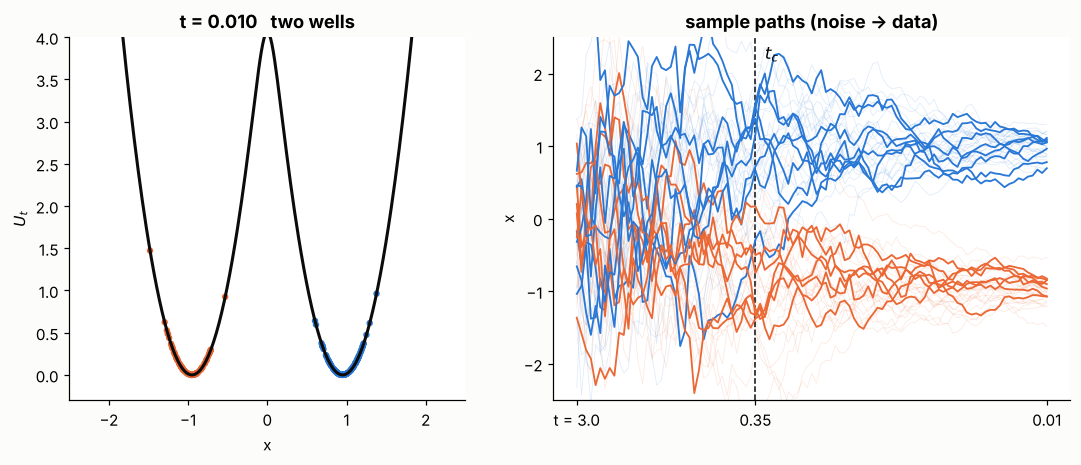

saved qe014_symmetry_breaking.gif (25 s)


In [10]:
def symmetry_breaking_animation(filename, n=300, frames=100, fps=20):
    x_end, ts_, path = reverse_diffusion(score_two_points, rng.standard_normal(n), steps=frames, t_min=0.01, keep=True)
    side = np.sign(path[-1]); colors = np.where(side > 0, BLUE, ORANGE)
    xs = np.linspace(-2.5, 2.5, 300)
    fig = plt.figure(figsize=(10, 4.4), facecolor=BG)
    axp, axt = fig.add_axes([0.06, 0.13, 0.36, 0.75]), fig.add_axes([0.5, 0.13, 0.47, 0.75])
    for k in range(0, n, 6):
        axt.plot(np.arange(frames + 1), path[:, k], color=colors[k], lw=0.5, alpha=0.15)
    k_c = np.argmin(np.abs(ts_ - t_c)); axt.axvline(k_c, color=INK, ls="--", lw=1)
    axt.text(k_c + 2, 2.2, "$t_c$", fontsize=11)
    axt.set_xticks([0, k_c, frames]); axt.set_xticklabels([f"t = {ts_[0]:.1f}", f"{t_c:.2f}", f"{ts_[-1]:.2f}"])
    axt.set_ylim(-2.5, 2.5); axt.set_ylabel("x"); axt.set_title("sample paths (noise → data)", fontweight="bold")
    axt.spines[["top", "right"]].set_visible(False)
    trail = [axt.plot([], [], color=colors[k], lw=1.2)[0] for k in range(0, n, 20)]
    U_line, = axp.plot([], [], color=INK, lw=2)
    dots = axp.scatter(np.zeros(n), np.zeros(n), s=10, c=colors)
    axp.set_xlim(-2.5, 2.5); axp.set_ylim(-0.3, 4); axp.set_xlabel("x"); axp.set_ylabel(r"$U_t$")
    axp.spines[["top", "right"]].set_visible(False)
    title = axp.set_title("", fontweight="bold")

    def draw(i):
        i = min(i, frames); t_ = ts_[i]; t_draw = max(t_, 0.05)          # keep the wells drawable near t = 0
        mu, var = M * np.exp(-t_draw), 1 - np.exp(-2 * t_draw)
        U = -np.log(0.5 * np.exp(-(xs - mu) ** 2 / (2 * var)) + 0.5 * np.exp(-(xs + mu) ** 2 / (2 * var)) + 1e-300)
        U = np.minimum(U - U.min(), 10); U_line.set_data(xs, U)
        Ux = np.interp(path[i], xs, U)
        dots.set_offsets(np.c_[path[i], Ux])
        for line, k in zip(trail, range(0, n, 20)):
            line.set_data(np.arange(i + 1), path[:i + 1, k])
        title.set_text(f"t = {t_:.3f}" + ("   one well" if t_ > t_c else "   two wells"))
        return []

    animation.FuncAnimation(fig, draw, frames=frames + 1 + fps).save(
        filename, writer=animation.PillowWriter(fps=fps), dpi=80, savefig_kwargs={"facecolor": BG})
    draw(frames); plt.show()

t0 = time.time()
symmetry_breaking_animation("qe014_symmetry_breaking.gif")
print(f"saved qe014_symmetry_breaking.gif ({time.time() - t0:.0f} s)")

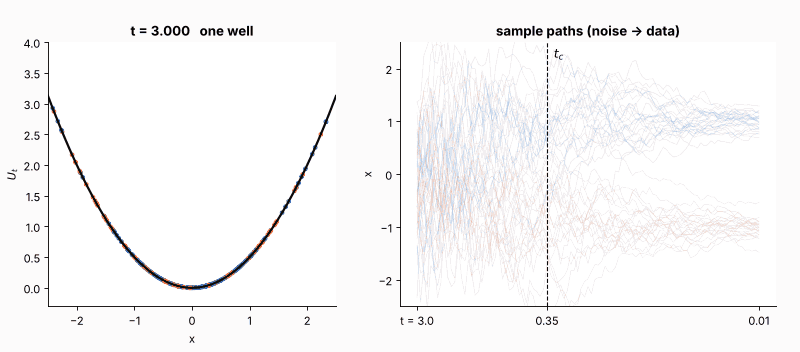

**2. Copying versus creating.** The same 600 noise samples flow back to data under the exact score (left) and a
smoothed score (right, h = 0.1). Crosses are the 16 training points.

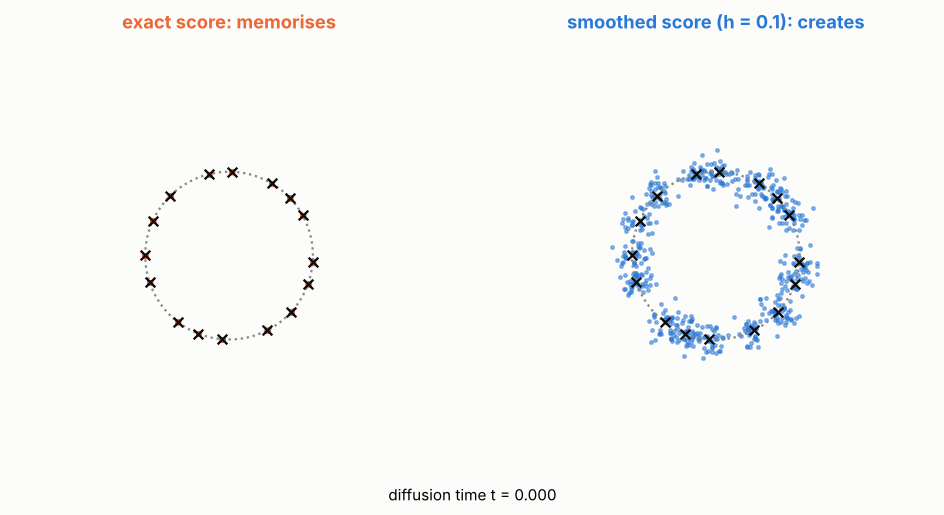

saved qe014_memorise_vs_create.gif (11 s)


In [11]:
def generation_animation(filename, h_smooth=0.1, n=600, frames=100, fps=20):
    start = rng.standard_normal((n, 2))
    runs = {}
    for h in (0.0, h_smooth):
        _, ts_, path = reverse_diffusion(make_score(h), start.copy(), steps=frames, keep=True)
        runs[h] = path
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), facecolor=BG)
    th = np.linspace(0, 2 * np.pi, 200); scat = []
    for a, (h, col, title) in zip(axes, [(0.0, ORANGE, "exact score: memorises"),
                                         (h_smooth, BLUE, f"smoothed score (h = {h_smooth}): creates")]):
        a.plot(np.cos(th), np.sin(th), ":", color=GRAY); a.scatter(*train_pts.T, marker="x", color=INK, s=40, zorder=3)
        scat.append(a.scatter(start[:, 0], start[:, 1], s=5, color=col, alpha=0.5))
        a.set_xlim(-2.6, 2.6); a.set_ylim(-2.6, 2.6); a.set_aspect("equal"); a.axis("off")
        a.set_title(title, fontweight="bold", color=col)
    clock = fig.text(0.5, 0.04, "", ha="center", fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 1))

    def draw(i):
        i = min(i, frames)
        for s_, h in zip(scat, (0.0, h_smooth)):
            s_.set_offsets(runs[h][i])
        clock.set_text(f"diffusion time t = {ts_[i]:.3f}")
        return []

    animation.FuncAnimation(fig, draw, frames=frames + 1 + fps).save(
        filename, writer=animation.PillowWriter(fps=fps), dpi=80, savefig_kwargs={"facecolor": BG})
    draw(frames); plt.show()

t0 = time.time()
generation_animation("qe014_memorise_vs_create.gif")
print(f"saved qe014_memorise_vs_create.gif ({time.time() - t0:.0f} s)")

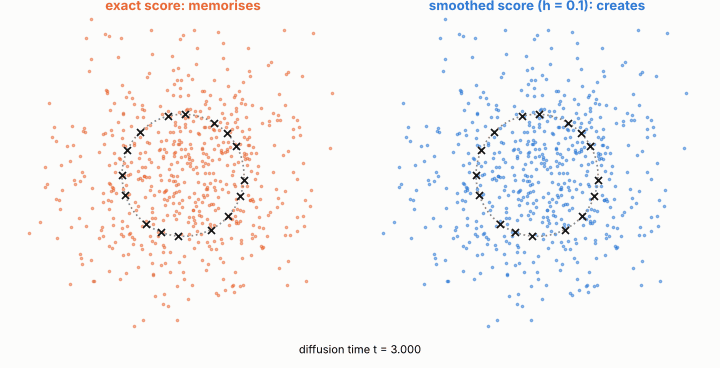

## Conclusions

1. **Exact answer.** The U(1) network's order parameter at $\sigma_W = 2$ is $c^\ast = 2.759005\ldots$, so
   $A = 2759005$, confirmed by iterating the layer map and by a finite network of width 2,000.
2. **Deep networks have phases.** At $\sigma_W = 1$ the signal goes from dying out to surviving, exactly like a magnet
   ordering, and simulations follow mean-field theory.
3. **A broken continuous symmetry protects information.** The relative phase of two inputs (a Goldstone mode)
   survives 100 layers, while an ordinary network keeps only a shrunken, scrambled trace of how its inputs were related.
4. **This makes very deep networks trainable without tricks.** At 64 layers with no skip connections or normalisation,
   U(1) and especially O(4) networks learn (O(4): 93–95%), while an ordinary network reaches 31% at best.
5. **Generation is symmetry breaking too.** In a diffusion model, samples commit to an outcome near a critical time
   $t_c = \frac12\ln(1+m^2)$. Whether the result copies or creates depends on how smooth the learned score is.

**Try it yourself:** use O(k) with larger k, add a recurrent version and test long-memory tasks, add a small
symmetry-breaking "field" (a bias) and watch the Goldstone mode lose its protection, or replace the blurred score in
B4 by a small trained network.

**Honest limits.** These are small experiments: an 8×8-digit data set, CPU-sized networks, a toy 2D data set and exact
scores instead of trained ones. They reproduce the qualitative claims of the papers below, not their full results.

### Further reading

* N. Iqbal, T. A. Keller, Y. Song, T. Miyato, M. Welling, *Spontaneous symmetry breaking and Goldstone modes for deep
  information propagation*, arXiv:2605.14685 (2026).
* N. Iqbal, M. Welling, *Topological defects propagate information in deep neural networks*, NeurIPS 2025 AI for
  Science Workshop.
* S. S. Schoenholz, J. Gilmer, S. Ganguli, J. Sohl-Dickstein, *Deep information propagation*, ICLR (2017).
* G. Raya, L. Ambrogioni, *Spontaneous symmetry breaking in generative diffusion models*, NeurIPS (2023).
* G. Biroli, T. Bonnaire, V. de Bortoli, M. Mézard, *Dynamical regimes of diffusion models*, Nature Communications 15,
  9957 (2024).